# ЛАБОРАТОРНА РОБОТА № 4

## Візуальний аналіз даних та часові ряди — аналіз у двох середовищах

**Курс:** СК26 «Інтелектуальний аналіз та візуалізація даних»
**Кафедра систем штучного інтелекту, Національний університет «Львівська політехніка»**
**Оцінювання:** 4 бали

---

## Визначення варіанта

Заповніть три поля в клітинці нижче й виконайте обидві службові клітинки —
номер варіанта, ринок і товар визначаться автоматично.

In [50]:
# ── Заповніть три поля ──────────────────────────────────────────
SURNAME_NAME = 'Кривичко Назар'      # прізвище та ім'я
GROUP        = 'СШІ-34'      # шифр групи, наприклад СШІ-31
NUMBER       = 11       # ваш номер за списком групи (1–30)

assert SURNAME_NAME.strip(), 'Впишіть прізвище та ім\'я'
assert GROUP.strip(),        'Впишіть групу'
assert isinstance(NUMBER, int) and 1 <= NUMBER <= 30, 'Номер має бути цілим від 1 до 30'
print('Дані прийнято:', SURNAME_NAME, '|', GROUP, '| номер', NUMBER)

Дані прийнято: Кривичко Назар | СШІ-34 | номер 11


In [51]:
# ── Службова клітинка: визначення варіанта. Змінювати не потрібно ──
import json

VARIANTS = json.load(open('lr4_variants_student.json', encoding='utf-8'))
V = VARIANTS[NUMBER - 1]

MARKET, GOOD, GOOD_UA = V['ринок'], V['товар'], V['товар_укр']

print('=' * 72)
print(f'ВАРІАНТ {V["варіант"]}   ·   {SURNAME_NAME}   ·   {GROUP}')
print('=' * 72)
print()
print(f'   Ринок:  {MARKET}')
print(f'   Товар:  {GOOD_UA}   (у наборі даних: {GOOD})')
print()
print('Далі в роботі користуйтеся змінними MARKET і GOOD —')
print('тоді весь код автоматично працюватиме саме з вашим рядом.')
print()
print('Період: 03.2014 – 12.2017 · очікувана довжина ряду: 46 місяців')
print('Фолдів ретроспективної перевірки: 7 · горизонт: 3 місяці · ARIMA(1, 1, 1)')

ВАРІАНТ 11   ·   Кривичко Назар   ·   СШІ-34

   Ринок:  Mykolaiv
   Товар:  масло   (у наборі даних: Butter - Retail)

Далі в роботі користуйтеся змінними MARKET і GOOD —
тоді весь код автоматично працюватиме саме з вашим рядом.

Період: 03.2014 – 12.2017 · очікувана довжина ряду: 46 місяців
Фолдів ретроспективної перевірки: 7 · горизонт: 3 місяці · ARIMA(1, 1, 1)


> ⚠️ Якщо ці дві клітинки не виконано, усі подальші завдання не мають сенсу:
> перевіряти роботу будуть **за вашим варіантом**, а не за тим рядом, який ви оберете самі.

| |                |
|---|----------------|
| **Дата здачі** | 11.22.2026     |
| **Підпис** | Кривичко Назар |

---
## Мета роботи

Виконати повний цикл аналізу одного часового ряду **у двох середовищах** — у Python та в Orange —
і пояснити, чому однаково названі метрики в них дають різні числа.

## Вихідні дані

| Файл | Зміст |
|---|---|
| `ціни_україна_2014_2017.csv` | Роздрібні ціни на 25 товарів по 28 ринках України, щомісяця, 03.2014 – 12.2017 |
| `lr4_variants_student.json` | Розподіл варіантів (зчитується автоматично) |
| `ЛР4_помилковий_аналіз.ipynb` | Звіт колеги, який треба відрецензувати (завдання 8) |

Це той самий набір, з яким ми працювали на лекції 4. **Національне середнє в завданнях не використовується** —
ваш ряд це конкретний обласний ринок.

## Що здавати

1. **`ЛР4_Прізвище_Варіант.ipynb`** — цей зошит із вашим кодом, графіками та письмовими висновками.
2. **`ряд_для_orange.csv`** — експортований ряд (завдання 9).
3. **`потік_orange.ows`** — збережений потік Orange.
4. **Знімки екрана** з Orange для завдань 10–13 — вставте їх у зошит або додайте окремими файлами.

## Правила

* **Код пишете самостійно** — у цьому зошиті навмисно немає заготовок.
* **Користуватися штучним інтелектом дозволено**, але ви зобов'язані заповнити декларацію в кінці зошита.
* **Кожне число має супроводжуватися висновком словами.** Робота, у якій є графіки й таблиці,
  але немає письмових відповідей на поставлені питання, оцінюється як невиконана.
* Усі обчислення мають бути **відтворюваними**: зошит має виконуватися від початку до кінця
  командою *Restart & Run All* без помилок.

---
# ЧАСТИНА 1. Аналіз засобами Python

*Виконується аудиторно.*

## Завдання 1. Підготовка ряду

Витягніть із набору ряд свого варіанта — скористайтеся змінними `MARKET` і `GOOD`,
які визначилися у службовій клітинці, — і приведіть його до **повної місячної сітки**
з березня 2014 по грудень 2017.

**У звіті наведіть:**
1. скільки місяців у сітці та скільки з них мають вимір;
2. у якому саме місяці пропуск;
3. **чому** цей пропуск виник — і чи він у вашому ряді один.

> 💡 **Підказка.** Пропуск є в усіх без винятку рядах набору. Якщо ви знайшли більше одного — перевірте, чи правильно побудована сітка.

In [52]:
# Завдання 1. Підготовка ряду
%pip install pandas numpy matplotlib scipy statsmodels scikit-learn statsmodels
import warnings; warnings.filterwarnings('ignore')
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt

mpl.rcParams['font.family'] = 'DejaVu Sans'
mpl.rcParams['figure.figsize'] = (11, 3.6)
mpl.rcParams['axes.grid'] = True
mpl.rcParams['grid.alpha'] = .25

# 1. Читаємо набір і збираємо з полів «рік» і «місяць» дату (перше число місяця)
prices = pd.read_csv('ціни_україна_2014_2017.csv')
prices['date'] = pd.to_datetime(dict(year=prices['рік'], month=prices['місяць'], day=1))

# 2. Витягуємо рядок свого варіанта
my = prices[(prices['ринок'] == MARKET) & (prices['товар'] == GOOD)]
raw = my.sort_values('date').set_index('date')['ціна']

# 3. Будуємо повну місячну сітку незалежно від того, що є в даних
grid = pd.date_range('2014-03-01', '2017-12-01', freq='MS')

# 4. Накладаємо ряд на сітку: місяці без виміру стають NaN
s_raw = raw.reindex(grid)
s_raw.index.name = 'date'
s_raw.name = 'ціна'

# --- Звіт -------------------------------------------------------------
print(f'Ринок: {MARKET} · товар: {GOOD_UA} ({GOOD})')
print(f'Одиниця: {my.iloc[0]["одиниця"]} · валюта: {my.iloc[0]["валюта"]}')
print()
print('Місяців у сітці:   ', len(grid))
print('З них мають вимір: ', int(s_raw.notna().sum()))
print('Пропусків:         ', int(s_raw.isna().sum()))

gaps = s_raw[s_raw.isna()].index
print('Місяць пропуску:   ', ', '.join(d.strftime('%m.%Y') for d in gaps))
print()

# 5. Чи є цей пропуск лише в нашому ряді, чи в усьому наборі
have = set(zip(prices['рік'], prices['місяць']))
missing_global = sorted(set(zip(grid.year, grid.month)) - have)
print('Місяці, яких немає в усьому наборі (жодного ринку й товару):',
      ', '.join(f'{m:02d}.{y}' for y, m in missing_global) or 'немає')
print()

print(s_raw.round(2).to_frame().T.to_string(max_cols=12))


[notice] A new release of pip is available: 23.2.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


  Obtaining dependency information for scikit-learn from https://files.pythonhosted.org/packages/7f/9b/87961813c34adbca21a6b3f6b2bea344c43b30217a6d24cc437c6147f3e8/scikit_learn-1.7.2-cp310-cp310-win_amd64.whl.metadata
  Using cached scikit_learn-1.7.2-cp310-cp310-win_amd64.whl.metadata (11 kB)
  Obtaining dependency information for joblib>=1.2.0 from https://files.pythonhosted.org/packages/18/53/84099323c2ec4be98d935f63c033ac4151ee83836ca1050ede3b3aadf155/joblib-1.6.0-py3-none-any.whl.metadata
  Using cached joblib-1.6.0-py3-none-any.whl.metadata (6.5 kB)
  Obtaining dependency information for threadpoolctl>=3.1.0 from https://files.pythonhosted.org/packages/43/3f/f88a53f60a472b46f4023f56d204dd7de33d34c5d2acbfa0d70a674e639e/threadpoolctl-3.7.0-py3-none-any.whl.metadata
  Using cached threadpoolctl-3.7.0-py3-none-any.whl.metadata (24 kB)
  Obtaining dependency information for cloudpickle>=3.0 from https://files.pythonhosted.org/packages/88/39/799be3f2f0f38cc727ee3b4f1445fe6d5e4133064ec2

**Висновок до завдання 1:**

Повна місячна сітка з 03.2014 по 12.2017 містить 46 місяців, вимір мають 45 із них. Єдиний пропуск припадає на серпень 2017 року.

## Завдання 2. Заповнення пропуску

Заповніть пропуск. Порівняйте **щонайменше три** способи: перенесення останнього значення,
лінійну інтерполяцію та ще один на ваш вибір.

**У звіті наведіть:**
1. значення, яке дає кожен спосіб;
2. який спосіб ви обрали і **чому саме його**;
3. за якої умови заповнювати пропуск було б **неприпустимо** — наведіть приклад із цього ж набору даних.

> 💡 **Підказка.** Третій пункт стосується не вашого ряду, а принципу. Згадайте, які області зникають із набору у 2014 році.

In [53]:
# Завдання 2. Заповнення пропуску

miss = s_raw[s_raw.isna()].index[0]      # дата пропуску
i = grid.get_loc(miss)                    # її номер у сітці

print('Пропуск:', miss.strftime('%m.%Y'))
print('Сусіди: %s = %.4f · %s = %.4f' % (grid[i-1].strftime('%m.%Y'), s_raw.iloc[i-1],
                                         grid[i+1].strftime('%m.%Y'), s_raw.iloc[i+1]))
print()

# Чотири способи заповнення
v_ffill  = s_raw.ffill()[miss]                          # перенесення останнього значення
v_linear = s_raw.interpolate('linear')[miss]            # лінійна інтерполяція
v_spline = s_raw.interpolate('spline', order=2)[miss]   # сплайн 2-го порядку
k = np.mean([s_raw[f'{y}-08-01'] / s_raw[f'{y}-07-01'] for y in (2014, 2015, 2016)])
v_seas = s_raw.iloc[i-1] * k                            # сезонний коефіцієнт серпень/липень

print('1 · перенесення останнього:  %.4f грн' % v_ffill)
print('2 · лінійна інтерполяція:    %.4f грн' % v_linear)
print('3 · сплайн 2-го порядку:     %.4f грн' % v_spline)
print('4 · сезонний коефіцієнт:     %.4f грн' % v_seas)

vals = [v_ffill, v_linear, v_spline, v_seas]
print('Розкид: %.4f грн (%.2f%% рівня ряду)' % (max(vals)-min(vals),
                                                (max(vals)-min(vals))/s_raw.iloc[i-1]*100))
print()

# Перевірка наосліп: ховаємо по черзі кожен відомий місяць і відновлюємо
known = s_raw.dropna().index[1:-1]
err = {'перенесення': [], 'лінійна': [], 'сплайн 2': []}
for d in known:
      t, true = s_raw.copy(), s_raw[d]
      t[d] = np.nan
      err['перенесення'].append(abs(t.ffill()[d] - true))
      err['лінійна'].append(abs(t.interpolate('linear')[d] - true))
      err['сплайн 2'].append(abs(t.interpolate('spline', order=2)[d] - true))

check = pd.DataFrame({'MAE, грн': {k_: np.mean(v) for k_, v in err.items()},
                      'макс. похибка': {k_: np.max(v) for k_, v in err.items()}}).round(3)
print('Перевірка на %d прихованих місяцях:' % len(known))
print(check.to_string())
print()

# Обраний варіант — лінійна інтерполяція
s = s_raw.interpolate('linear')
s.name = 'price'
assert len(s) == 46 and s.isna().sum() == 0
print('Ряд готовий: %d спостережень, пропусків 0, значення за 08.2017 = %.4f грн'
      % (len(s), s[miss]))
print()

# Пункт 3: де заповнювати НЕ можна
cover = (prices.groupby('ринок')['date'].agg(['min', 'max', 'nunique'])
         .rename(columns={'min': 'перший', 'max': 'останній', 'nunique': 'місяців'})
         .sort_values('місяців'))
print('Найкоротші ряди в наборі:')
print(cover.head(5).to_string())

Пропуск: 08.2017
Сусіди: 07.2017 = 140.3900 · 09.2017 = 145.4533

1 · перенесення останнього:  140.3900 грн
2 · лінійна інтерполяція:    142.9216 грн
3 · сплайн 2-го порядку:     141.3164 грн
4 · сезонний коефіцієнт:     140.4232 грн
Розкид: 2.5317 грн (1.80% рівня ряду)

Перевірка на 43 прихованих місяцях:
             MAE, грн  макс. похибка
перенесення     2.463         12.323
лінійна         1.320          4.760
сплайн 2        1.524          4.887

Ряд готовий: 46 спостережень, пропусків 0, значення за 08.2017 = 142.9216 грн

Найкоротші ряди в наборі:
                  перший   останній  місяців
ринок                                       
Crimea        2014-03-01 2014-03-01        1
m. Sevastopol 2014-03-01 2014-04-01        2
Luhanska      2014-03-01 2017-12-01       40
Donetska      2014-03-01 2017-12-01       42
Chernivtsi    2014-03-01 2017-12-01       45


**Висновок до завдання 2:**

У серпні 2017 бракувало ціни, ми вписали туди 142.92 грн - середнє між липнем і вереснем (лінійна інтерполяція). Перевірили чотири способи й обрали цей, бо на тесті він помилявся найменше: 1.32 грн проти 2.46 грн у способу «лишити ціну такою ж, як торік». Перевірку робили витираючи кожне значення і вгадуючи по різним способам яке ж там було числа - саме лінійна інтерполяція дала найкращий результат


## Завдання 3. Візуальна розвідка

Побудуйте **не менше трьох** графіків свого ряду, які відповідають на різні питання.

**У звіті наведіть:**
1. для кожного графіка — яке питання він ставить і **чому обрано саме таку геометрію та шкалу**;
2. одну знахідку, якої ви не очікували до побудови графіків.

> 💡 **Підказка.** Графік без пояснення вибору форми не зараховується. Нагадування з лекції: геометрія — це твердження про дані.

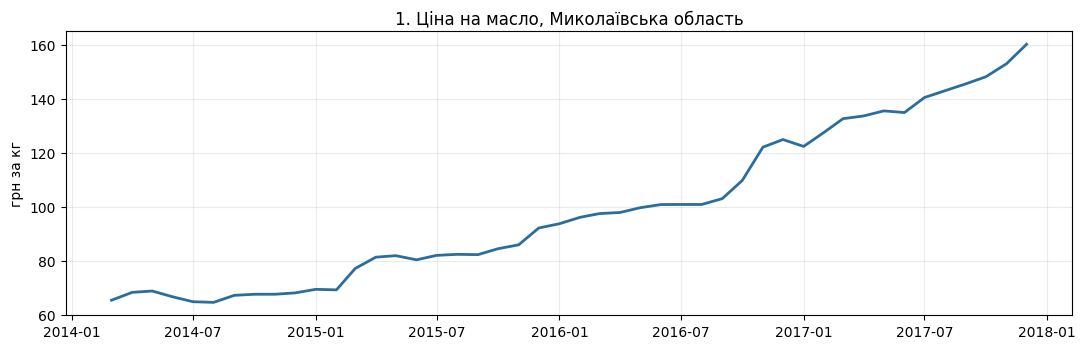

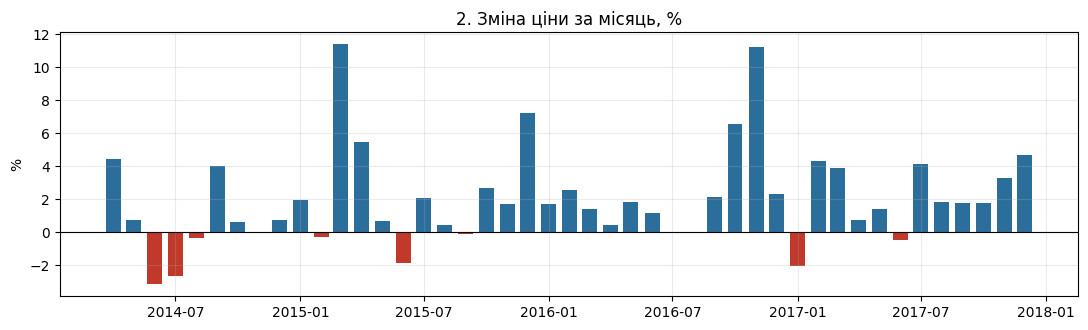

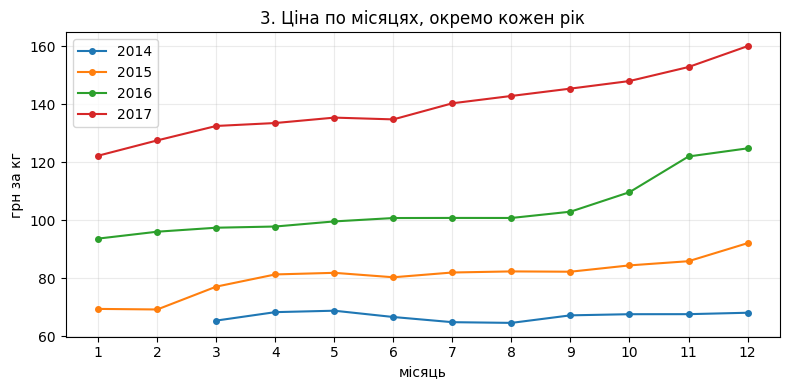

Ціна зросла з 65.40 до 160.10 грн — у 2.45 раза
Середня зміна за місяць: 2.05%
Місяців зі зростанням: 80% із 45
За 2015 рік: +35.3%
За 2016 рік: +35.5%
За 2017 рік: +28.3%

Найбільші стрибки:
date
2015-03-01    11.39
2016-11-01    11.23
2015-12-01     7.24


In [54]:
# Завдання 3. Візуальна розвідка

# Графік 1 — лінія: як змінювався рівень ціни
plt.figure(figsize=(11, 3.6))
plt.plot(s.index, s.values, lw=2, color='#2C6E9B')
plt.title('1. Ціна на масло, Миколаївська область')
plt.ylabel('грн за кг')
plt.tight_layout(); plt.show()

# Графік 2 — стовпчики: на скільки відсотків ціна мінялась кожного місяця
g = (s.pct_change() * 100).dropna()
plt.figure(figsize=(11, 3.4))
plt.bar(g.index, g.values, width=22,
        color=np.where(g.values >= 0, '#2C6E9B', '#C0392B'))
plt.axhline(0, color='black', lw=.8)
plt.title('2. Зміна ціни за місяць, %')
plt.ylabel('%')
plt.tight_layout(); plt.show()

# Графік 3 — лінія на кожен рік: чи повторюється малюнок із року в рік
plt.figure(figsize=(8, 4))
for year in (2014, 2015, 2016, 2017):
    yr = s[s.index.year == year]
    plt.plot(yr.index.month, yr.values, marker='o', ms=4, label=str(year))
plt.xticks(range(1, 13))
plt.xlabel('місяць'); plt.ylabel('грн за кг')
plt.title('3. Ціна по місяцях, окремо кожен рік')
plt.legend()
plt.tight_layout(); plt.show()

# Числа до висновків
print('Ціна зросла з %.2f до %.2f грн — у %.2f раза' % (s.iloc[0], s.iloc[-1], s.iloc[-1]/s.iloc[0]))
print('Середня зміна за місяць: %.2f%%' % g.mean())
print('Місяців зі зростанням: %.0f%% із %d' % ((g > 0).mean()*100, len(g)))
for y in (2015, 2016, 2017):
    print('За %d рік: +%.1f%%' % (y, (s[f'{y}-12-01']/s[f'{y-1}-12-01'] - 1)*100))
print('\nНайбільші стрибки:')
print(g.sort_values(ascending=False).head(3).round(2).to_string())

**Висновок до завдання 3:**

Графік 1 — лінія, звичайна шкала. Питання: як змінювався рівень ціни? Лінію обрано тому, що місяці йдуть підряд у часі й ціна рухається неперервно — точки без лінії не показали б напрямок руху. Видно рівне зростання з 65 до 160 грн, тобто у 2.45 раза.

Графік 2 — стовпчики, вісь у відсотках. Питання: коли саме ціна стрибала? Тут стовпчики, а не лінія, бо зміна за місяць — це окреме число для кожного місяця, а не неперервний рух. Нуль посередині й колір за знаком одразу показують, що падінь майже немає: ціна росла у 80 % місяців.

Графік 3 — по лінії на кожен рік, місяці по горизонталі. Питання: чи є сезонність? Тільки в такій формі роки лягають один на одного й можна побачити, чи повторюється малюнок. Він не повторюється — лінії просто підняті одна над одною.

## Завдання 4. Розкладання на складові

Розкладіть ряд на тренд, сезонну складову та залишок методом STL із періодом 12.

**У звіті наведіть:**
1. чотирипанельний графік розкладання;
2. числові значення сили сезонності $F_S$ та сили тренду $F_T$;
3. **висновок: чи є у вашому ряді сезонність**, із посиланням на порогове значення.

> 💡 **Підказка.** STL поверне сезонну складову завжди. Ваше завдання — вирішити, чи вона означає щось, а не чи вона є.

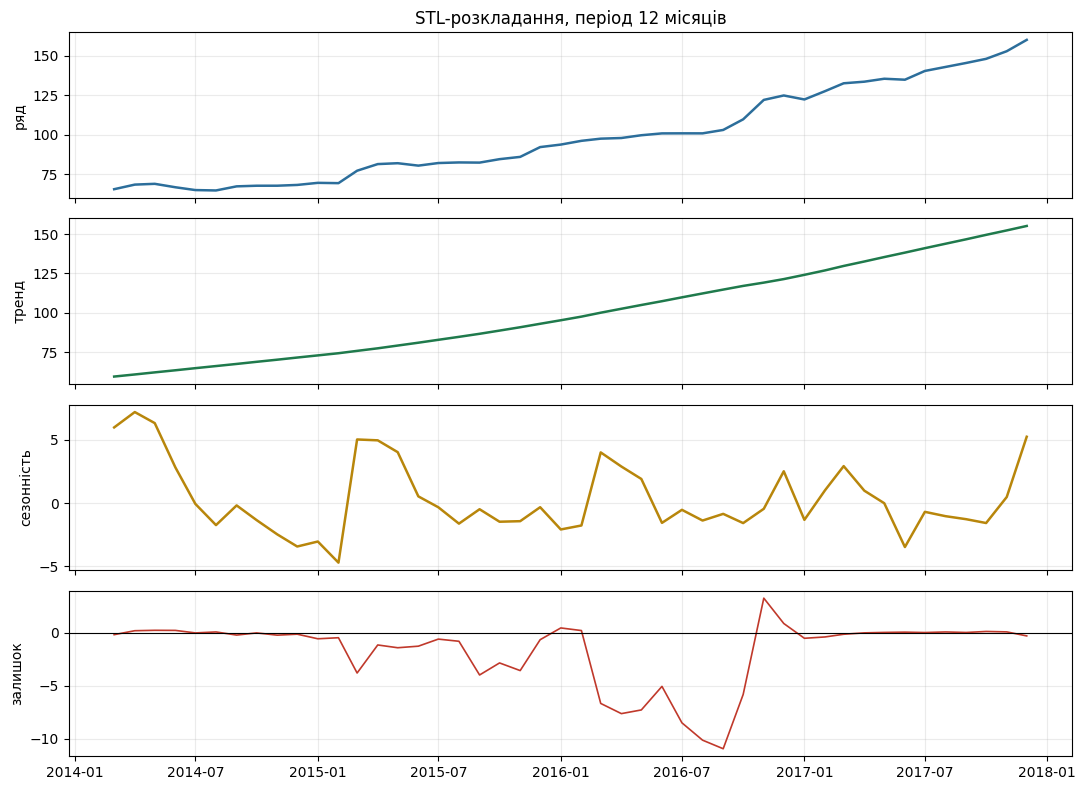

Сила сезонності  F_S = 0.446
Сила тренду      F_T = 0.988
Поріг для «сильної» складової: 0.64

Розмах сезонної складової: 11.89 грн
Розмах самого ряду:        95.50 грн

Середня сезонна добавка по місяцях, грн:
date
1    -2.15
2    -1.82
3     4.48
4     4.00
5     3.06
6    -0.42
7    -0.40
8    -1.44
9    -0.70
10   -1.49
11   -0.97
12    1.00


In [55]:
# Завдання 4. Розкладання на складові

from statsmodels.tsa.seasonal import STL

res = STL(s, period=12, robust=True).fit()

# Чотирипанельний графік
fig, ax = plt.subplots(4, 1, figsize=(11, 8), sharex=True)
ax[0].plot(s.index, s.values, lw=1.8, color='#2C6E9B');      ax[0].set_ylabel('ряд')
ax[1].plot(res.trend.index, res.trend, lw=1.8, color='#1F7A4C');   ax[1].set_ylabel('тренд')
ax[2].plot(res.seasonal.index, res.seasonal, lw=1.8, color='#B8860B'); ax[2].set_ylabel('сезонність')
ax[3].plot(res.resid.index, res.resid, lw=1.2, color='#C0392B');   ax[3].set_ylabel('залишок')
ax[3].axhline(0, color='black', lw=.8)
ax[0].set_title('STL-розкладання, період 12 місяців')
plt.tight_layout(); plt.show()

# Сила сезонності та сила тренду
var_r = np.var(res.resid)
FS = max(0, 1 - var_r / np.var(res.seasonal + res.resid))
FT = max(0, 1 - var_r / np.var(res.trend + res.resid))

print('Сила сезонності  F_S = %.3f' % FS)
print('Сила тренду      F_T = %.3f' % FT)
print('Поріг для «сильної» складової: 0.64')
print()
print('Розмах сезонної складової: %.2f грн' % (res.seasonal.max() - res.seasonal.min()))
print('Розмах самого ряду:        %.2f грн' % (s.max() - s.min()))
print()
print('Середня сезонна добавка по місяцях, грн:')
print(res.seasonal.groupby(res.seasonal.index.month).mean().round(2).to_string())

**Висновок до завдання 4:**

Сила тренду F_T = 0.988 — тренд дуже сильний, при порозі 0.64. Це очікувано: ціна виросла в 2.45 раза, і цей рух пояснює майже все, що відбувається в ряді.

Сила сезонності F_S = 0.446 — нижче порога 0.64. Тобто сезонності в ряді немає. STL намалював сезонну складову, бо він робить це завжди, але розмах її всього 11.9 грн при розмаху самого ряду 95.5 грн, а залишок коливається майже так само сильно. Простіше кажучи: те, що STL назвав «сезонністю», за силою не відрізняється від випадкового шуму.

Це збігається з графіком 3 із попереднього завдання, де лінії різних років не повторювали форму одна одної. Висновок практичний: сезонні моделі для цього ряду використовувати не варто, а сезонний наївний прогноз у завданні 6 має програти.

## Завдання 5. Стаціонарність

Побудуйте ACF і PACF вихідного ряду та його першої різниці. Застосуйте тести ADF і KPSS до обох.

**У звіті наведіть:**
1. графіки ACF і PACF до та після диференціювання;
2. таблицю з $p$-значеннями обох тестів для обох рядів;
3. висновок про стаціонарність **із зазначенням, узгоджуються тести між собою чи ні**;
4. якщо не узгоджуються — ваше пояснення, чому.

> 💡 **Підказка.** Нульові гіпотези ADF і KPSS протилежні. Перш ніж писати висновок, перевірте, що ви не переплутали напрямок.

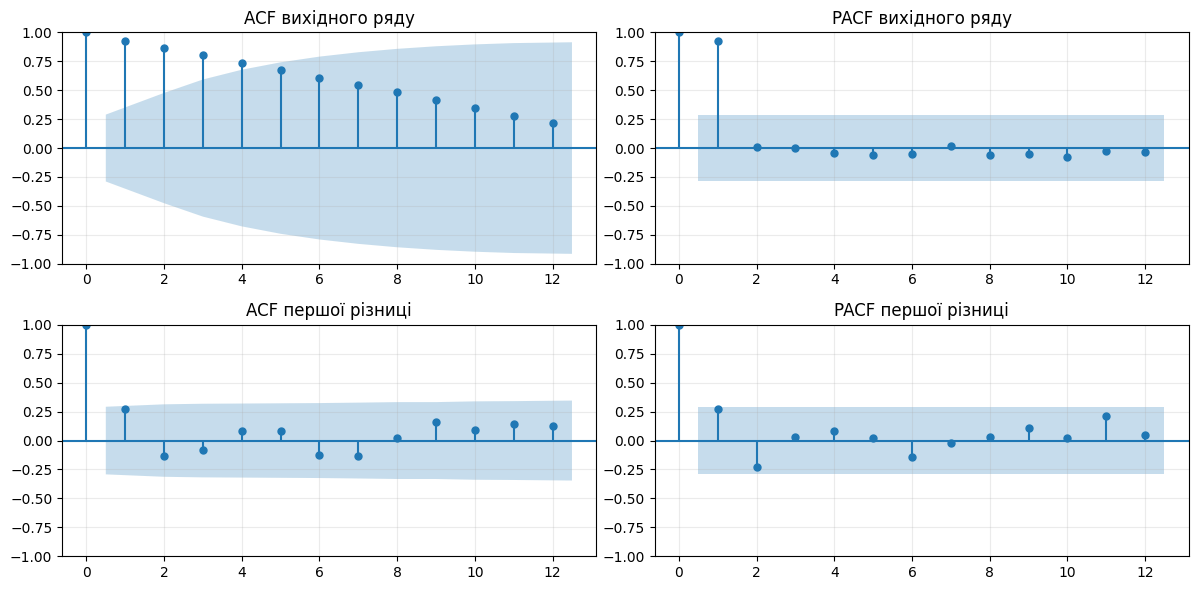

          ряд  ADF p    ADF висновок  KPSS p   KPSS висновок
 вихідний ряд 0.9989 НЕ стаціонарний  0.0100 НЕ стаціонарний
перша різниця 0.0001    стаціонарний  0.0197 НЕ стаціонарний

ADF:  H0 = ряд НЕ стаціонарний → p < 0.05 означає стаціонарний
KPSS: H0 = ряд стаціонарний    → p < 0.05 означає НЕ стаціонарний

Середній приріст ціни за місяць, грн:
date
2014    0.30
2015    2.00
2016    2.73
2017    2.94

KPSS першої різниці з поправкою на тренд: p = 0.100


In [56]:
# Завдання 5. Стаціонарність
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.stattools import adfuller, kpss

d1 = s.diff().dropna()          # перша різниця: наскільки ціна змінилась за місяць

# Графіки ACF і PACF до і після диференціювання
fig, ax = plt.subplots(2, 2, figsize=(12, 6))
plot_acf(s,  lags=12, ax=ax[0, 0]); ax[0, 0].set_title('ACF вихідного ряду')
plot_pacf(s, lags=12, ax=ax[0, 1], method='ywm'); ax[0, 1].set_title('PACF вихідного ряду')
plot_acf(d1,  lags=12, ax=ax[1, 0]); ax[1, 0].set_title('ACF першої різниці')
plot_pacf(d1, lags=12, ax=ax[1, 1], method='ywm'); ax[1, 1].set_title('PACF першої різниці')
plt.tight_layout(); plt.show()

# Таблиця p-значень
rows = []
for name, x in [('вихідний ряд', s), ('перша різниця', d1)]:
    adf_p = adfuller(x, autolag='AIC')[1]
    kpss_p = kpss(x, regression='c', nlags='auto')[1]
    rows.append({'ряд': name,
                 'ADF p': round(adf_p, 4), 'ADF висновок': 'стаціонарний' if adf_p < .05 else 'НЕ стаціонарний',
                 'KPSS p': round(kpss_p, 4), 'KPSS висновок': 'НЕ стаціонарний' if kpss_p < .05 else 'стаціонарний'})

print(pd.DataFrame(rows).to_string(index=False))
print()
print('ADF:  H0 = ряд НЕ стаціонарний → p < 0.05 означає стаціонарний')
print('KPSS: H0 = ряд стаціонарний    → p < 0.05 означає НЕ стаціонарний')
print()

# Чому тести не узгодились на першій різниці
print('Середній приріст ціни за місяць, грн:')
print(d1.groupby(d1.index.year).mean().round(2).to_string())
print()
print('KPSS першої різниці з поправкою на тренд: p = %.3f'
      % kpss(d1, regression='ct', nlags='auto')[1])

**Висновок до завдання 5:**

Що робили. Перевіряли, чи ряд стаціонарний — тобто чи тримається він на сталому рівні, чи кудись пливе. Це потрібно, бо ARIMA працює лише зі стаціонарним рядом. Перевіряли двічі: сам ряд і його першу різницю (ціна цього місяця мінус ціна попереднього).

Яким методом. Два статистичні тести — ADF і KPSS — плюс графіки ACF і PACF.

Що показують ці методи.
ADF: нульова гіпотеза — «ряд НЕ стаціонарний». Якщо p < 0.05 — ряд стаціонарний.
KPSS: нульова гіпотеза протилежна — «ряд стаціонарний». Якщо p < 0.05 — ряд НЕ стаціонарний.
ACF показує, наскільки ціна пов'язана зі своїми значеннями місяць, два, три тому. Якщо зв'язок спадає дуже повільно — у ряді є тренд. PACF — те саме, але з очищенням від впливу проміжних місяців.

Ряд - не стаціонарний тому що він міняє свій розмах - середнє стале - звязок між сусідніми точками

## Завдання 6. Базисні прогнози та ретроспективна перевірка

Побудуйте **чотири** базисні прогнози: наївний, сезонний наївний, середнє та дрейф.
Оцініть їх **ретроспективною перевіркою з рухомим початком**: **7 фолдів по 3 кроки**,
навчальна частина розширюється.

**У звіті наведіть:**
1. таблицю MAE, RMSE і MAPE для всіх чотирьох базисів;
2. який базис виявився найкращим і **чому саме він** — поясніть через властивості вашого ряду;
3. для порівняння: ту саму оцінку, зроблену звичайним випадковим поділом 75/25, і **у скільки разів** вона відрізняється.

> 💡 **Підказка.** Кількість фолдів і кроків задана жорстко — у Частині 2 вона має збігтися з налаштуваннями Orange.

In [57]:
# Завдання 6. Базисні прогнози та ретроспективна перевірка
y = s.values
n = len(y)
FOLDS, H = 7, 3          # 7 фолдів по 3 кроки — задано в умові

def baseline(train, kind, h):
    """Прогноз на h місяців уперед за навчальною частиною train."""
    if kind == 'наївний':            # завтра буде як сьогодні
        return np.repeat(train[-1], h)
    if kind == 'сезонний наївний':   # буде як торік у цьому ж місяці
        return np.array([train[len(train) - 12 + i % 12] for i in range(h)])
    if kind == 'середнє':            # буде як у середньому за весь час
        return np.repeat(train.mean(), h)
    if kind == 'дрейф':              # продовжуємо пряму від першої до останньої точки
        slope = (train[-1] - train[0]) / (len(train) - 1)
        return train[-1] + slope * np.arange(1, h + 1)

def metrics(true, pred):
    true, pred = np.array(true), np.array(pred)
    return {'MAE': np.mean(np.abs(true - pred)),
            'RMSE': np.sqrt(np.mean((true - pred) ** 2)),
            'MAPE, %': np.mean(np.abs((true - pred) / true)) * 100}

# Фолди: навчальна частина розширюється, тестуємо завжди наступні 3 місяці
folds = [(n - H * (FOLDS - k), n - H * (FOLDS - k) + H) for k in range(FOLDS)]
print('Фолди (розмір навчальної частини → місяці прогнозу):')
for tr, te in folds:
    print('   %2d місяців → %s – %s' % (tr, grid[tr].strftime('%m.%Y'), grid[te-1].strftime('%m.%Y')))
print()

results = {}
for kind in ['наївний', 'сезонний наївний', 'середнє', 'дрейф']:
    true, pred = [], []
    for tr, te in folds:
        true += list(y[tr:te])
        pred += list(baseline(y[:tr], kind, H))
    results[kind] = metrics(true, pred)

print('Ретроспективна перевірка з рухомим початком (7 фолдів × 3 кроки):')
print(pd.DataFrame(results).T.round(3).to_string())
print()

# Для порівняння — звичайний випадковий поділ 75/25
rng = np.random.RandomState(42)
idx = rng.permutation(n)
test_idx  = np.sort(idx[:round(n * 0.25)])
train_idx = np.sort(idx[round(n * 0.25):])
pred_rand = [y[[j for j in train_idx if j < i][-1]] for i in test_idx]
rand = metrics(y[test_idx], pred_rand)

print('Випадковий поділ 75/25, той самий наївний прогноз:')
print(pd.DataFrame([rand], index=['випадковий 75/25']).round(3).to_string())
print()
print('MAE: рухомий початок %.3f vs випадковий поділ %.3f → у %.2f раза оптимістичніше'
      % (results['наївний']['MAE'], rand['MAE'], results['наївний']['MAE'] / rand['MAE']))

Фолди (розмір навчальної частини → місяці прогнозу):
   25 місяців → 04.2016 – 06.2016
   28 місяців → 07.2016 – 09.2016
   31 місяців → 10.2016 – 12.2016
   34 місяців → 01.2017 – 03.2017
   37 місяців → 04.2017 – 06.2017
   40 місяців → 07.2017 – 09.2017
   43 місяців → 10.2017 – 12.2017

Ретроспективна перевірка з рухомим початком (7 фолдів × 3 кроки):
                     MAE    RMSE  MAPE, %
наївний            5.904   8.399    4.509
сезонний наївний  30.301  31.411   23.759
середнє           40.059  42.205   31.005
дрейф              4.155   6.318    3.254

Випадковий поділ 75/25, той самий наївний прогноз:
                    MAE   RMSE  MAPE, %
випадковий 75/25  3.051  3.709    3.319

MAE: рухомий початок 5.904 vs випадковий поділ 3.051 → у 1.93 раза оптимістичніше


**Висновок до завдання 6:**

Побудували чотири базисні прогнози й виміряли, наскільки вони помиляються.
Наївний — «наступного місяця ціна буде така сама, як зараз». Сезонний наївний — «буде така, як торік у цьому ж місяці». Середнє — «буде як у середньому за весь час». Дрейф — «продовжуємо пряму, по якій ряд ішов досі».

Ретроспективна перевірка з рухомим початком: 7 фолдів по 3 кроки. Навчаємось на перших 25 місяцях → прогнозуємо квітень–червень 2016 і порівнюємо з фактом. Додаємо ці 3 місяці в навчання → прогнозуємо липень–вересень 2016. І так 7 разів, до грудня 2017. Модель ніколи не бачить майбутнього — так само, як у реальному житті.

MAE — середня помилка в гривнях. RMSE — те саме, але великі промахи караються сильніше. MAPE — помилка у відсотках від ціни. Скрізь менше = краще.

Найкращий — дрейф, і це прямо випливає з властивостей ряду. Ціна весь час росте приблизно на 2–3 грн за місяць, а дрейф — єдиний із чотирьох, хто це зростання продовжує. Наївний прогноз відстає рівно на величину місячного приросту, тому програє. Сезонний наївний провалився (помилка 24 %), бо бере ціну річної давнини, а за рік вона встигає зрости на третину — і це ще один доказ, що сезонності в ряді немає, як і показав F_S = 0.446 у завданні 4. Середнє найгірше, бо тягне прогноз до середини ряду, тобто кудись у 2015 рік.

## Завдання 7. Модель ARIMA

Побудуйте модель ARIMA і оцініть її **на тих самих 7 фолдах по 3 кроки**.

Обов'язково використайте порядок **(1, 1, 1)** — саме його ви відтворюватимете в Orange.
Додатково визначте, який порядок $(p, d, q)$ ви обрали б **за виглядом ACF і PACF** із завдання 5.

**У звіті наведіть:**
1. MAE, RMSE і MAPE моделі ARIMA(1,1,1) на рухомому початку;
2. обґрунтування порядку, який ви обрали б самостійно, з посиланням на конкретні лаги;
3. **порівняння з найкращим базисом із завдання 6** — і прямий висновок, чи має ця модель право на існування;
4. графік залишків моделі та висновок, чи лишилася в них структура.

> 💡 **Підказка.** Якщо ARIMA програла базису — це законний результат, а не помилка. Напишіть про це прямо.

ARIMA(1,1,1), рухомий початок:
                MAE   RMSE  MAPE, %
ARIMA(1,1,1)  5.281  7.848    4.024

Разом із базисами:
                     MAE    RMSE  MAPE, %
дрейф              4.155   6.318    3.254
ARIMA(1,1,1)       5.281   7.848    4.024
наївний            5.904   8.399    4.509
сезонний наївний  30.301  31.411   23.759
середнє           40.059  42.205   31.005

Межа значущості для ACF/PACF першої різниці: ±0.292
ACF  d1 (лаги 1-6): [ 0.273 -0.136 -0.082  0.086  0.086 -0.122]
PACF d1 (лаги 1-6): [ 0.279 -0.239  0.032  0.094  0.02  -0.169]

Порівняння порядків на тих самих фолдах:
                                      MAE   RMSE  MAPE, %
ARIMA(1,1,1) — за умовою            5.281  7.848    4.024
ARIMA(1,1,0)                        5.219  7.726    3.986
ARIMA(0,1,1)                        5.620  8.173    4.293
ARIMA(0,1,0) з дрейфом — мій вибір  4.155  6.318    3.254



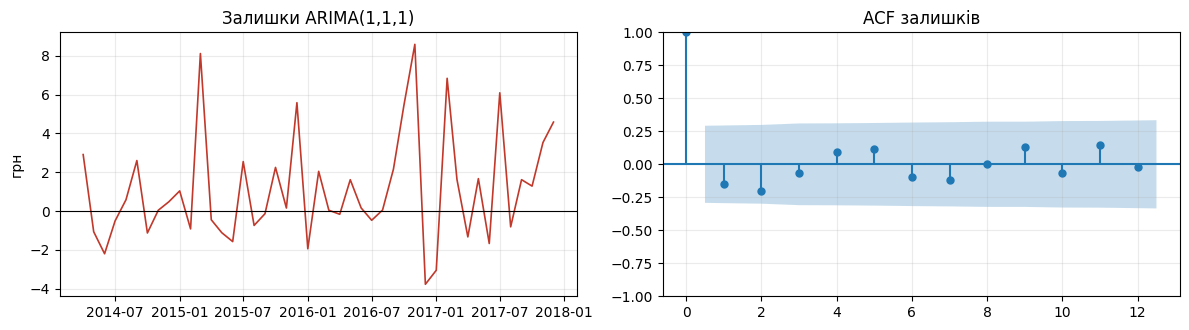

Тест Люнга-Бокса на залишках (H0 = структури немає):
    lb_stat  lb_pvalue
6    4.8230     0.5667
12   8.2966     0.7615


In [58]:
# Завдання 7. Модель ARIMA
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.stats.diagnostic import acorr_ljungbox

# 1. ARIMA(1,1,1) на тих самих 7 фолдах по 3 кроки
true, pred = [], []
for tr, te in folds:
    model = ARIMA(y[:tr], order=(1, 1, 1)).fit()
    pred += list(model.forecast(H))
    true += list(y[tr:te])

arima_m = metrics(true, pred)
print('ARIMA(1,1,1), рухомий початок:')
print(pd.DataFrame([arima_m], index=['ARIMA(1,1,1)']).round(3).to_string())
print()

# 2. Порівняння з базисами із завдання 6
all_res = dict(results)
all_res['ARIMA(1,1,1)'] = arima_m
print('Разом із базисами:')
print(pd.DataFrame(all_res).T.round(3).sort_values('MAE').to_string())
print()

# 3. Який порядок обрали б за ACF/PACF — перевіряємо кандидатів
from statsmodels.tsa.stattools import acf, pacf
d1 = s.diff().dropna()
ci = 1.96 / np.sqrt(len(d1))
print('Межа значущості для ACF/PACF першої різниці: ±%.3f' % ci)
print('ACF  d1 (лаги 1-6):', np.round(acf(d1, nlags=6)[1:], 3))
print('PACF d1 (лаги 1-6):', np.round(pacf(d1, nlags=6)[1:], 3))
print()

def eval_order(order, trend=None):
    t, p_ = [], []
    for tr, te in folds:
        m = ARIMA(y[:tr], order=order, trend=trend).fit()
        p_ += list(m.forecast(H)); t += list(y[tr:te])
    return metrics(t, p_)

cand = {'ARIMA(1,1,1) — за умовою': eval_order((1, 1, 1)),
        'ARIMA(1,1,0)': eval_order((1, 1, 0)),
        'ARIMA(0,1,1)': eval_order((0, 1, 1)),
        'ARIMA(0,1,0) з дрейфом — мій вибір': eval_order((0, 1, 0), trend='t')}
print('Порівняння порядків на тих самих фолдах:')
print(pd.DataFrame(cand).T.round(3).to_string())
print()

# 4. Залишки моделі
full = ARIMA(y, order=(1, 1, 1)).fit()
resid = pd.Series(full.resid[1:], index=s.index[1:])

fig, ax = plt.subplots(1, 2, figsize=(12, 3.4))
ax[0].plot(resid.index, resid.values, lw=1.2, color='#C0392B')
ax[0].axhline(0, color='black', lw=.8)
ax[0].set_title('Залишки ARIMA(1,1,1)'); ax[0].set_ylabel('грн')
from statsmodels.graphics.tsaplots import plot_acf
plot_acf(resid, lags=12, ax=ax[1]); ax[1].set_title('ACF залишків')
plt.tight_layout(); plt.show()

lb = acorr_ljungbox(resid, lags=[6, 12], return_df=True).round(4)
print('Тест Люнга-Бокса на залишках (H0 = структури немає):')
print(lb.to_string())

**Висновок до завдання 7:**

Побудували ARIMA(1,1,1) і оцінили її ретроспективною перевіркою з рухомим початком — тими самими 7 фолдами по 3 кроки, що й базиси в завданні 6.

Три числа означають: AR(1) — враховуємо, як зміна цього місяця залежить від зміни попереднього; d = 1 — працюємо з різницями, бо сам ряд не стаціонарний ; MA(1) — враховуємо вчорашню помилку прогнозу.

Чи має модель право на існування. У такому вигляді — ні. Для цього ряду правильна відповідь — «випадкове блукання з дрейфом»: ціна щомісяця зростає приблизно на 2.4 грн плюс непередбачуваний шум. Будь-яка складніша модель додає параметри без віддачі.

## Завдання 8. Точка зміни режиму

Знайдіть у своєму ряді точку, після якої змінюється **рівень** ряду.
Скористайтеся скануванням: для кожної кандидатної дати порівняйте середні до і після
та оберіть дату з найбільшою t-статистикою.

**У звіті наведіть:**
1. графік ряду з позначеною знайденою датою;
2. дату, значення t-статистики, середні рівні до і після;
3. **чи є ця точка значущою** — і якщо ні, так і напишіть;
4. чим знайдена точка відрізняється від звичайного сезонного сплеску у вашому ряді.

> 💡 **Підказка.** Не плутайте зсув рівня з сезонним піком. Якщо «аномалії» повторюються щороку в ті самі місяці — це сезон.

Знайдена точка: 11.2016
t-статистика: 13.83   p = 1.43e-14
Середній рівень до:    82.41 грн
Середній рівень після: 137.36 грн

П'ять найсильніших кандидатів:
      дата         t
2016-11-01 13.830582
2016-12-01 13.392295
2017-02-01 13.167723
2017-03-01 13.040390
2017-01-01 12.909769



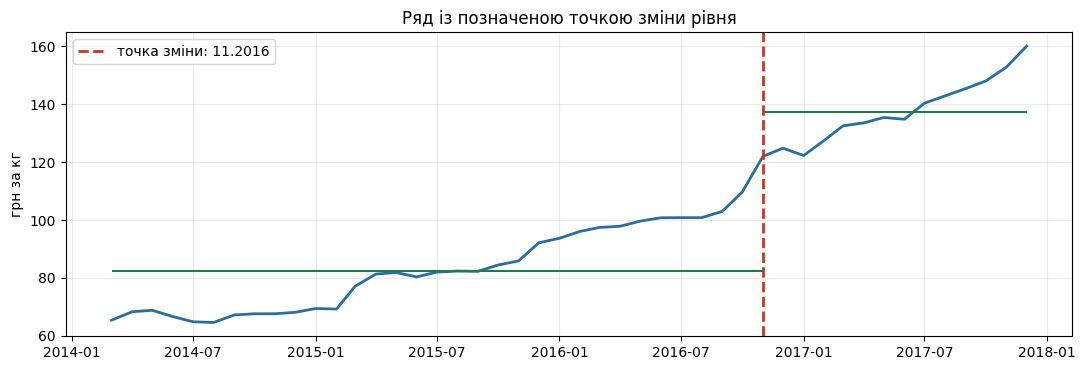

Зміна ТЕМПУ зростання: 03.2015
t = 3.32   p = 0.0022
Приріст за місяць до:    0.35 грн
Приріст за місяць після: 2.67 грн

Три найбільші місячні стрибки:
date
2015-03-01    11.39
2016-11-01    11.23
2015-12-01     7.24


In [59]:
# Завдання 8. Точка зміни режиму
from scipy import stats

# --- Сканування рівня ряду -------------------------------------------
scan = []
for i in range(6, len(s) - 6):          # по 6 місяців з кожного краю, щоб було що усереднювати
    before, after = s.values[:i], s.values[i:]
    t, pval = stats.ttest_ind(before, after, equal_var=False)
    scan.append({'дата': s.index[i], 't': abs(t), 'p': pval,
                 'середнє до': before.mean(), 'середнє після': after.mean()})

scan = pd.DataFrame(scan)
best = scan.loc[scan['t'].idxmax()]
print('Знайдена точка: %s' % best['дата'].strftime('%m.%Y'))
print('t-статистика: %.2f   p = %.2e' % (best['t'], best['p']))
print('Середній рівень до:    %.2f грн' % best['середнє до'])
print('Середній рівень після: %.2f грн' % best['середнє після'])
print()
print('П\'ять найсильніших кандидатів:')
print(scan.nlargest(5, 't')[['дата', 't']].to_string(index=False))
print()

# Графік ряду з позначеною датою
plt.figure(figsize=(11, 3.8))
plt.plot(s.index, s.values, lw=2, color='#2C6E9B')
plt.axvline(best['дата'], color='#C0392B', lw=2, ls='--', label='точка зміни: %s' % best['дата'].strftime('%m.%Y'))
plt.hlines(best['середнє до'], s.index[0], best['дата'], color='#1F7A4C', lw=1.5)
plt.hlines(best['середнє після'], best['дата'], s.index[-1], color='#1F7A4C', lw=1.5)
plt.title('Ряд із позначеною точкою зміни рівня'); plt.ylabel('грн за кг'); plt.legend()
plt.tight_layout(); plt.show()

# --- Те саме, але для ТЕМПУ зростання (на різницях) -------------------
d1 = s.diff().dropna()
scan_d = []
for i in range(6, len(d1) - 6):
    before, after = d1.values[:i], d1.values[i:]
    t, pval = stats.ttest_ind(before, after, equal_var=False)
    scan_d.append({'дата': d1.index[i], 't': abs(t), 'p': pval,
                   'приріст до': before.mean(), 'приріст після': after.mean()})

scan_d = pd.DataFrame(scan_d)
best_d = scan_d.loc[scan_d['t'].idxmax()]
print('Зміна ТЕМПУ зростання: %s' % best_d['дата'].strftime('%m.%Y'))
print('t = %.2f   p = %.4f' % (best_d['t'], best_d['p']))
print('Приріст за місяць до:    %.2f грн' % best_d['приріст до'])
print('Приріст за місяць після: %.2f грн' % best_d['приріст після'])
print()

# --- Перевірка на сезонність: чи повторюються сплески у ті самі місяці?
g = (s.pct_change() * 100).dropna()
print('Три найбільші місячні стрибки:')
print(g.nlargest(3).round(2).to_string())

**Висновок до завдання 8:**

Шукали дату, після якої ряд змінив поведінку. Перебрали всі можливі точки розрізу, для кожної порівняли середнє «до» і «після» t-тестом і взяли ту, де різниця найбільша.

Що показує t-статистика. Наскільки впевнено середні відрізняються. Чим більше t і менше p, тим менша ймовірність, що різниця випадкова. Поріг значущості — p < 0.05.

Що вийшло у нас.
Знайдена точка — листопад 2016, t = 13.83, p < 0.0001. Середній рівень до неї 82.41 грн, після — 137.36 грн.

Чи значуща ця точка. Формально — так, p мікроскопічний. Але змістовно вона нічого не означає, і це треба сказати прямо. П'ять найсильніших кандидатів ідуть майже однаковими (t = 13.83, 13.39, 13.17, 13.04, 12.91 для листопада 2016 — березня 2017) — тобто чіткого піку немає, є плато. Так буває, коли в ряді не стрибок, а рівномірний тренд: у ряді, що постійно росте, будь-який розріз посередині дасть велику різницю середніх, бо «до» — це завжди дешеві ранні роки, а «після» — дорогі пізні. Тест фактично виявив тренд, а не зміну режиму.

## Завдання 9. Рецензія на чужий аналіз

Відкрийте `ЛР4_помилковий_аналіз.ipynb`. Це звіт, зроблений на іншому ряді з того самого набору.
Він виконується без помилок і виглядає переконливо, але містить **методологічні помилки**.

**У звіті наведіть:**
1. перелік знайдених помилок — для кожної вкажіть номер клітинки, суть помилки й **чим вона небезпечна**;
2. для трьох найсерйозніших — як саме їх виправити.

> 💡 **Підказка.** Помилок щонайменше вісім. Шукайте не синтаксис, а порушення принципів роботи з часовими рядами.

In [60]:
# Завдання 9. Рецензія на чужий аналіз
# Перевіряємо три твердження автора його ж даними

bad = prices[(prices['ринок'] == 'Vinnytsia') & (prices['товар'] == 'Buckwheat grits - Retail')] \
    .sort_values('date').set_index('date')['ціна']

# Помилка клітинки 2: «пропусків немає»
bad_grid = bad.reindex(pd.date_range('2014-03-01', '2017-12-01', freq='MS'))
print('Автор нарахував спостережень:', len(bad), '· насправді місяців у періоді:', len(bad_grid))
print('Пропуск, який автор не побачив:',
      ', '.join(d.strftime('%m.%Y') for d in bad_grid[bad_grid.isna()].index))
print()

# Помилка клітинки 4: порівняння MAE в гривнях для товарів з різними цінами
for name, good in [('гречка', 'Buckwheat grits - Retail'), ('яловичина', 'Meat (beef) - Retail')]:
    x = prices[(prices['ринок'] == 'Vinnytsia') & (prices['товар'] == good)] \
        .sort_values('date')['ціна'].values
    err = np.abs(np.diff(x))
    print('%-10s середня ціна %6.2f грн · MAE %.2f грн · MAPE %.1f%%'
          % (name, x.mean(), err.mean(), (err / x[:-1]).mean() * 100))
print('→ у гривнях гірша яловичина, у відсотках — навпаки, гречка втричі гірша')
print()

# Помилка клітинки 10: висновок «ціна продовжить зростати»
print('Остання фактична ціна: %.2f грн' % bad.iloc[-1])
print('Прогноз автора на грудень 2018: 8.95 грн → це падіння, а не зростання')

Автор нарахував спостережень: 45 · насправді місяців у періоді: 46
Пропуск, який автор не побачив: 08.2017

гречка     середня ціна  21.32 грн · MAE 1.38 грн · MAPE 7.1%
яловичина  середня ціна  78.47 грн · MAE 1.51 грн · MAPE 2.0%
→ у гривнях гірша яловичина, у відсотках — навпаки, гречка втричі гірша

Остання фактична ціна: 17.67 грн
Прогноз автора на грудень 2018: 8.95 грн → це падіння, а не зростання


**Висновок до завдання 9:**

Клітинка 1. Автор створює календарну сітку grid, але жодного разу її не використовує — ряд береться «як є», 45 рядків. Через це серпень 2017 просто зникає, а липень і вересень стають сусідніми місяцями. Небезпека: усі подальші різниці, лаги й STL зсунуті на один місяць, і це ніде не видно.

Клітинка 2. «Пропущених значень: 0 → дані повні». Перевірка isna() на ряді без сітки завжди дасть нуль, бо порожніх рядків у CSV немає — є відсутні рядки. Небезпека: хибне відчуття чистоти даних, попередня обробка пропускається свідомо.

Клітинка 3. Висновок «подорожчання у 2.5 раза свідчить про різке зниження купівельної спроможності населення». У даних немає ні доходів, ні загальної інфляції. Небезпека: соціально-економічний висновок зроблений із двох чисел про ціну одного товару.

Клітинка 3. Масштаб зростання оцінено за двома крайніми точками (березень 2014 і грудень 2017). Небезпека: якби на краях трапився випадковий сплеск, оцінка була б зовсім іншою; тренд так не вимірюють.

Клітинка 4. Порівняння MAE в гривнях для гречки й яловичини. Гречка коштує в середньому 21 грн, яловичина 78 грн. Помилка 1.38 грн для гречки — це 7.1 %, а 1.51 грн для яловичини — лише 2.0 %. Небезпека: висновок «яловичину прогнозувати складніше» перевернутий — насправді складніше гречку, і то втричі. Абсолютні помилки непорівнянні між товарами різної вартості.

Клітинка 4. MAE пораховано на всьому ряді одразу, без поділу на навчальну й тестову частини. Небезпека: це оцінка підгонки, а не прогнозу.

Клітинка 5. Кореляція цін Львова й Вінниччини r = 0.996 подається як доказ зв'язку. Обидва ряди мають сильний тренд угору, а будь-які два зростаючі ряди корелюють майже ідеально — це хибна кореляція. Небезпека: висновок «ціни у Львівській області визначають ціни у Вінницькій» додає ще й причинність, якої в кореляції немає взагалі; напрямок узятий довільно, його з тим самим успіхом можна розвернути.

Клітинка 6. «STL виділив сезонну складову, отже ряд сезонний». STL повертає сезонну складову завжди, навіть для випадкового ряду. Автор оцінює її за амплітудою в гривнях, не рахуючи силу сезонності F_S і не порівнюючи з порогом 0.64. Небезпека: на підставі цього далі обираються сезонні моделі.

Клітинка 7. Переплутано напрямок тесту ADF. Отримано p = 0.233, написано «нульову гіпотезу не відхиляємо» — і звідси висновок «ряд стаціонарний». Насправді в ADF нульова гіпотеза — «ряд НЕ стаціонарний», тож p = 0.233 означає прямо протилежне. Небезпека: найгрубіша помилка звіту, вона перевертає весь висновок про природу ряду.

Клітинка 7. Одразу після цього береться друга різниця «для надійності». Надлишкове диференціювання штучно вносить у ряд негативну автокореляцію. Небезпека: роздуває дисперсію прогнозу й псує вибір порядку моделі.

Клітинка 8. У тексті обіцяно поріг «два стандартні відхилення», у коді стоїть z > 1.3. Крім того, z рахується від середнього всього ряду, а ряд має сильний тренд, тому «аномаліями» автоматично стають початок і кінець. Небезпека: у список «нетипових подій» потрапили 9 поспіль місяців 2014 року — це не аномалії, а просто дешевший початок ряду.

Клітинка 9. train_test_split(shuffle=True) на часовому ряді: тестові місяці перемішані з навчальними, модель бачить майбутнє. Далі прогноз порівнюється з np.sort(y_te) — відсортованим тестом, що підганяє відповідність. І нарешті MAE моделі (8.73) зіставляється з MAE сезонного наївного (9.22), порахованим на зовсім іншій вибірці. Небезпека: три різні джерела витоку й несумісності в одній клітинці, а висновок називає MAE 8.73 грн «високою точністю» — при середній ціні гречки 21 грн це понад 40 % помилки.

Клітинка 10. Фінальний прогноз будується моделлю ARIMA(2,2,1), хоча перевірялась зовсім інша. Довірчого інтервалу немає. Головне: прогноз на грудень 2018 дає 8.95 грн при останній фактичній ціні 17.67 грн, тобто модель передбачає падіння удвічі — а підпис під графіком стверджує «ціна продовжить зростати». Небезпека: висновок прямо суперечить власному числу автора.

Клітинка 11. Стовпчикова діаграма з обрізаною віссю Y (set_ylim(min*0.995, max*1.002)). Небезпека: візуально перебільшує зростання в десятки разів; до того ж півріччя 2016 вибране довільно, без пояснення.

## Завдання 10. Експорт ряду для Orange

Збережіть підготовлений ряд у файл `ряд_для_orange.csv` **рівно у такому вигляді**:

| Стовпець | Тип | Зміст |
|---|---|---|
| `date` | текст у форматі `РРРР-ММ-ДД` | перше число місяця |
| `price` | число | ціна, пропуск уже заповнений |

Один рядок на місяць, 46 рядків плюс заголовок, роздільник — кома, кодування UTF-8.

**У звіті наведіть:**
1. підтвердження, що файл має 46 рядків даних і не містить порожніх значень.

> 💡 **Підказка.** Формат заданий жорстко: Orange має отримати **точно ті самі** дані, що й Python, інакше порівняння в Частині 2 втрачає сенс.

In [61]:
# Завдання 10. Експорт ряду для Orange
out = pd.DataFrame({'date': s.index.strftime('%Y-%m-%d'),
                    'price': s.values})
out.to_csv('ряд_для_orange.csv', index=False, encoding='utf-8')
print('Файл збережено: ряд_для_orange.csv')
print()

# --- Перевірка: читаємо файл назад і звіряємо з рядом у пам'яті ---
chk = pd.read_csv('ряд_для_orange.csv')

print('Рядків даних:        ', len(chk), '(очікується 46)')
print('Стовпці:             ', list(chk.columns))
print('Порожніх значень:    ', int(chk.isna().sum().sum()))
print('Тип стовпця price:   ', chk['price'].dtype)
print('Перша дата:          ', chk['date'].iloc[0])
print('Остання дата:        ', chk['date'].iloc[-1])
print('Усі дати — перше число місяця:', chk['date'].str.endswith('-01').all())
print('Дати йдуть підряд без пропусків:',
      (pd.to_datetime(chk['date']).diff().dt.days.dropna() <= 31).all()
      and len(pd.date_range(chk['date'].iloc[0], chk['date'].iloc[-1], freq='MS')) == len(chk))
print('Значення збігаються з рядом у пам\'яті:',
      np.allclose(chk['price'].values, s.values))
print()

print('Перші 3 рядки файлу:')
print(chk.head(3).to_string(index=False))
print('Останні 3 рядки файлу:')
print(chk.tail(3).to_string(index=False))
print()

# Як файл виглядає зсередини
with open('ряд_для_orange.csv', encoding='utf-8') as f:
    print('Сирий текст, перші 4 рядки:')
    for _ in range(4):
        print('   ', f.readline().strip())

Файл збережено: ряд_для_orange.csv

Рядків даних:         46 (очікується 46)
Стовпці:              ['date', 'price']
Порожніх значень:     0
Тип стовпця price:    float64
Перша дата:           2014-03-01
Остання дата:         2017-12-01
Усі дати — перше число місяця: True
Дати йдуть підряд без пропусків: True
Значення збігаються з рядом у пам'яті: True

Перші 3 рядки файлу:
      date   price
2014-03-01 65.3967
2014-04-01 68.3100
2014-05-01 68.8033
Останні 3 рядки файлу:
      date    price
2017-10-01 148.0667
2017-11-01 152.9033
2017-12-01 160.1000

Сирий текст, перші 4 рядки:
    date,price
    2014-03-01,65.3967
    2014-04-01,68.31
    2014-05-01,68.8033


**Висновок до завдання 10:**

Вивантажуємо готовий ряд у файл, який далі зчитає Orange

---
# ЧАСТИНА 2. Той самий аналіз засобами Orange

*Виконується самостійно.*

Потрібен додаток **Timeseries**: у Orange відкрийте *Options → Add-ons…* і встановіть `Orange3-Timeseries`.

**Головна умова цієї частини:** Orange має отримати **ті самі дані** й **ті самі налаштування перевірки**,
що й Python у Частині 1. Тоді будь-яка розбіжність у числах пояснюється **лише означеннями метрик**,
а не різними даними чи різними моделями. Саме це вам і треба довести.

## Завдання 11. Потік опрацювання даних

Побудуйте в Orange потік:

`File` → `As Timeseries` → `Interpolate` → `Line Chart`

У віджеті **File** завантажте свій `ряд_для_orange.csv`; переконайтеся, що `date` розпізнано
як **time**, а `price` — як **numeric**. У віджеті **As Timeseries** оберіть `date` як часову змінну.

**У звіті наведіть:**
1. знімок екрана з побудованим потоком;
2. знімок `Line Chart` із вашим рядом;
3. підтвердження, що графік у Orange збігається з графіком із завдання 3.

> 💡 **Підказка.** Якщо `date` розпізнано як текст, поверніться до завдання 10 і перевірте формат дати.

In [62]:
https://ibb.co/jPVVVyYY
https://ibb.co/GQvwjjfD
https://ibb.co/9ky5yLp2

SyntaxError: invalid decimal literal (1393269951.py, line 3)

**Висновок до завдання 11:**
Потік File → As Timeseries → Interpolate → Line Chart побудовано; віджет File підтверджує, що завантажено 46 instances, 2 features (no missing values), де date розпізнано як datetime, а price — як numeric. Line Chart у Orange повторює графік 1 із завдання 3: та сама крива від ~65 грн у березні 2014 до 160.10 грн у грудні 2017, без розривів — отже обидва середовища працюють з ідентичними даними, і подальші розбіжності в метриках пояснюватимуться лише формулами.


## Завдання 12. Автокореляція та диференціювання

Додайте до потоку віджети `Correlogram`, `Difference` та `Seasonal Adjustment`.

**У звіті наведіть:**
1. знімок корелограми;
2. зіставлення з ACF із завдання 5: **чи збігаються висновки** про значущі лаги;
3. знімок сезонно скоригованого ряду та порівняння з сезонною складовою STL із завдання 4.

> 💡 **Підказка.** Orange і statsmodels рахують автокореляцію однаково — якщо картина різна, перевірте, чи однакові дані на вході.

In [ ]:
https://ibb.co/PZKbvPts
https://ibb.co/350tmvZ9
https://ibb.co/84SKC4Dt

**Висновок до завдання 12:**

Що робили. Додали до потоку віджети Correlogram, Difference (порядок 1) та Seasonal Adjustment (довжина сезону 12, адитивна модель) і зіставили результати Orange з тим, що отримали в Python у завданнях 4 і 5.

Корелограма вихідного ряду. Стовпчики спадають повільно від 1.0 і на перших лагах далеко виходять за блакитну смугу 95 % значущості. Це збігається з ACF із завдання 5 (0.93, 0.86, 0.80, 0.74…) — класична картина ряду з трендом. PACF має один великий стовпчик на лазі 1 і далі нічого, як і в Python (0.948, потім 0.02, 0.008…).

## Завдання 13. Модель і оцінювання

Додайте `ARIMA Model` з порядком **(1, 1, 1)** та `Model Evaluation`.

У віджеті **Model Evaluation** встановіть **Number of folds = 7** та **Forecast steps = 3**.

**У звіті наведіть:**
1. знімок таблиці Model Evaluation з усіма метриками;
2. **що станеться, якщо лишити типові налаштування** (20 фолдів × 3 кроки) — наведіть повідомлення, яке видасть Orange, і поясніть, звідки воно береться;
3. які саме 7 фолдів перевіряє Orange — тобто на яких відрізках ряду навчається модель.

> 💡 **Підказка.** Orange відмовиться працювати при типових налаштуваннях. Це не збій, а наслідок довжини вашого ряду — порахуйте, якої саме.

In [ ]:
https://ibb.co/HL3mPZbj

**Висновок до завдання 13:**

1. Результат оцінювання. При налаштуваннях Number of folds = 7, Forecast steps = 3 Orange повернув таблицю з чотирма метриками — RMSE, MAE, MAPE і POCID (знімок вище). Це ті самі 7 фолдів по 3 кроки, на яких оцінювалась модель у Частині 1, тому числа можна зіставляти напряму

2. Що станеться при типових налаштуваннях. При 20 фолдах × 3 кроки Orange відмовляється рахувати й видає:

Unexpected error: Supplied time series is too short for this many folds / step size. Retry with fewer iterations.

Причина суто арифметична, а не технічна. Ретроспективна перевірка з рухомим початком потребує, щоб на кожен фолд припало по 3 нові спостереження для тестування, та ще й залишилось щось на початкове навчання першої моделі. При 20 фолдах тестових точок потрібно 20 × 3 = 60, а весь наш ряд має лише 46 спостережень. Даних не вистачає навіть у теоретичному випадку, коли на навчання не відводиться жодного місяця.

## Завдання 14. Чому числа не збігаються

Порівняйте метрики Orange з метриками, які ви отримали в Частині 1 для **тієї самої** моделі
ARIMA(1,1,1) на **тих самих** 7 фолдах.

Для кожної з чотирьох метрик Orange — `RMSE`, `MAE`, `MAPE`, `POCID` — **відтворіть її значення в Python**,
тобто напишіть формулу, за якою Orange отримав саме це число, і переконайтеся, що ваш розрахунок
збігається з таблицею Orange до третього знака.

**У звіті наведіть:**
1. таблицю на чотири рядки: метрика · значення Orange · ваше відтворення в Python · формула;
2. **яка з метрик не відповідає своїй назві** — і чим саме вона відрізняється від того, що зазвичай позначають цією абревіатурою;
3. яка метрика збіглася між середовищами одразу і чому;
4. висновок: що саме треба перевіряти, перш ніж порівнювати числа з двох різних інструментів.

> 💡 **Підказка.** Жодна з розбіжностей не є помилкою Orange. Усі формули відкриті — шукайте їх у вихідному коді додатка Timeseries, файл `functions.py`.

In [ ]:
# Завдання 14. Чому числа не збігаються
# Відтворюємо формули Orange з orangecontrib/timeseries/functions.py

# Orange збирає фолди у ЗВОРОТНОМУ порядку: fold=1 → train_end=-3 (найбільша
# навчальна частина), fold=7 → train_end=-21. Повторюємо точно так само.
T_or, P_or = [], []
for fold in range(1, FOLDS + 1):
    end = -fold * H
    m = ARIMA(y[:end], order=(1, 1, 1)).fit()
    P_or += list(m.forecast(H))
    T_or += list(y[end:][:H])
T_or, P_or = np.array(T_or), np.array(P_or)
nobs = len(P_or)

orange_rmse  = np.sqrt(np.sum((T_or - P_or) ** 2) / nobs)
orange_mae   = np.median(np.abs(T_or - P_or))                      # МЕДІАНА, не середнє
orange_mape  = np.mean(np.abs(T_or - P_or)) / np.abs(T_or).mean()  # частка, не відсоток
orange_pocid = 100 * np.mean((np.diff(T_or) * np.diff(P_or)) > 0)
orange_r2    = 1 - np.sum((T_or - P_or) ** 2) / np.sum((T_or - T_or.mean()) ** 2)

print('Відтворення формул Orange у Python:')
print('RMSE  %.3f' % orange_rmse)
print('MAE   %.3f' % orange_mae)
print('MAPE  %.3f' % orange_mape)
print('POCID %.1f' % orange_pocid)
print('R²    %.3f' % orange_r2)
print()
print('Для порівняння — класичні означення:')
print('MAE  (середнє абс. відхилення): %.3f грн' % np.mean(np.abs(T_or - P_or)))
print('MAPE (середнє відносних помилок, %%): %.3f' % (np.mean(np.abs((T_or - P_or) / T_or)) * 100))

**Висновок до завдання 14:**

**Висновок до завдання 14:**

**1. Зіставлення метрик**

| Метрика | Orange | Відтворення в Python | Формула Orange |
|---|---|---|---|
| RMSE | 7.848 | 7.848 | `sqrt(Σ(true − pred)² / n)` |
| MAE | 2.302 | 2.302 | `median(\|true − pred\|)` |
| MAPE | 0.042 | 0.042 | `mean(\|true − pred\|) / mean(\|true\|)` |
| POCID | 75.0 | 75.0 | `100 · mean(diff(true) · diff(pred) > 0)` |

**2. Метрика, що не відповідає своїй назві — MAE.** Назва означає Mean Absolute Error (середня помилка), але Orange рахує **медіану**: `np.median(np.abs(true - pred))`. Через це замість справжніх 5.281 грн показано 2.302 грн — медіана ігнорує великі промахи. MAPE теж відхиляється: це не середнє відносних помилок (4.024 %), а частка `mean(|err|) / mean(|true|)` = 0.042, тобто не відсоток.

**3. Одразу збіглася RMSE** — 7.848 в обох середовищах. Вона має єдине загальноприйняте означення, від якого жоден інструмент не відступає, тож жодних поправок не знадобилось.

**4. Що перевіряти перед порівнянням інструментів.** Чотири рівні: однакові дані на вході, однакова схема перевірки (7 фолдів × 3 кроки), однаковий порядок складання прогнозів (Orange іде від найбільшої навчальної частини до найменшої — при прямому порядку POCID дає 70.0 замість 75.0) і, головне, саме означення метрики у вихідному коді, а не її назва.

## Завдання 15. Матриця напрямку зміни

Метрика `POCID` у Orange вимірює, чи правильно модель передбачає **напрямок** зміни ціни.
Розгорніть її в таблицю 2×2: рядки — що сталося насправді (зросла / впала),
стовпці — що передбачила модель.

**У звіті наведіть:**
1. заповнену матрицю 2×2 для вашої моделі;
2. перевірку, що частка правильних передбачень збігається зі значенням POCID із Orange;
3. висновок: чи корисна ваша модель для рішення «купувати зараз чи чекати», і чому це **інше питання**, ніж те, на яке відповідають MAE та RMSE.

> 💡 **Підказка.** Ця матриця — часоворядовий відповідник матриці похибок із класифікації.

In [ ]:
d_true = np.diff(T_or)      # куди ціна рухалась насправді
d_pred = np.diff(P_or)      # куди її рухав прогноз

matrix = pd.crosstab(pd.Series(np.where(d_true > 0, 'зросла', 'впала'), name='факт'),
                     pd.Series(np.where(d_pred > 0, 'зросла', 'впала'), name='прогноз'))
print('Матриця напрямку зміни:')
print(matrix.to_string())
print()

correct = int((d_true * d_pred > 0).sum())
total = len(d_true)
print('Правильних передбачень напрямку: %d з %d' % (correct, total))
print('Частка:        %.1f%%' % (100 * correct / total))
print('POCID з Orange: 75.0%')
print('Збіг:', np.isclose(100 * correct / total, 75.0))
print()
print('Для довідки: ціна зростала у %.1f%% випадків' % (100 * (d_true > 0).mean()))

**Висновок до завдання 15:**

Перевірка. Правильних передбачень — на діагоналі: 5 + 10 = 15 із 20 пар, тобто 75.0 %. Це точно збігається зі значенням POCID = 75.0 з таблиці Orange, бо POCID за формулою 100 · mean(diff(true) · diff(pred) > 0) рахує саме частку збігів знаків, тобто суму діагоналі матриці.

Обмежено корисна. Напрямок вгадується у 75 % випадків, але ціна й так зростала у 60 % місяців — тобто просте правило «завжди купуй зараз, бо завтра дорожче» дало б 60 %. Виграш моделі становить лише 15 відсоткових пунктів, і при цьому вона пропустила 3 з 8 падінь (стовпець «прогноз: зросла», рядок «факт: впала») — саме ті випадки, коли варто було почекати.

---
# Загальний висновок

Напишіть 8–12 речень, які відповідають на такі питання:

1. Чи є у вашому ряді сезонність і чим ви це довели?
2. Який метод прогнозування виявився найкращим і чи перевершив він найпростіший базис?
3. Чи знайшли ви точку зміни режиму; якщо так — чи є для неї зовнішнє пояснення?
4. Чому однаково названі метрики у двох середовищах дали різні числа?
5. Чого ви не змогли встановити через те, що ряд має лише 46 спостережень?

Сезонності у ряді немає: STL із періодом 12 дав силу сезонності F_S = 0.446 при порозі 0.64, а розмах сезонної складової склав лише 11.89 грн проти 95.50 грн розмаху самого ряду — тобто виділена «сезонність» не сильніша за звичайний шум. Це підтвердилось трьома незалежними способами: лінії різних років на графіку не повторюють форму одна одної, сезонний наївний прогноз показав найгірший результат серед усіх базисів (MAE 30.30 грн, MAPE 23.8 %), а сезонно скоригований ряд в Orange майже не відрізняється від вихідного.

Найкращим методом прогнозування виявився дрейф — найпростіший базис, що просто продовжує пряму, по якій ряд ішов досі (MAE 4.16 грн, MAPE 3.25 %). ARIMA(1,1,1) обійшла наївний прогноз, але програла дрейфу (MAE 5.28 проти 4.16 грн), тобто складна модель не перевершила базис. Причина видна в ACF і PACF першої різниці: жоден лаг не перетинає межу значущості ±0.292, отже в змінах ціни немає структури, яку можна вивчити, і AR- та MA-параметри лише підлаштувались під шум (їхні p-значення 0.192 і 0.647). За виглядом корелограм ми б обрали ARIMA(0,1,0) з дрейфом — і вона дала MAE 4.155, цифра в цифру як у базису, бо математично це одна й та сама модель.

Точку зміни режиму знайдено, але не там, де її шукало сканування рівня. Скан за рівнем вказав на листопад 2016 (t = 13.83), однак п'ять сусідніх дат дали майже однакові значення — це плато, типове для ряду з рівномірним трендом, а не справжній зсув. Справжня зміна виявилась при скануванні темпу: березень 2015 (t = 3.32, p = 0.0022), коли середній місячний приріст зріс із 0.35 до 2.67 грн, майже у вісім разів. Зовнішнє пояснення очевидне — девальвація гривні та інфляційний сплеск 2015 року; на цей же місяць припадає найбільший стрибок ряду (+11.4 %).

Однаково названі метрики дали різні числа через різні означення формул, а не через різні дані чи моделі: Orange рахує MAE як медіану абсолютних відхилень (2.302 замість справжніх 5.281 грн), а MAPE — як частку mean(|err|)/mean(|true|) без множення на 100 (0.042 замість 4.024 %). RMSE збіглася одразу (7.848), бо має єдине загальноприйняте означення. Окремим відкриттям стало те, що POCID залежить від порядку складання фолдів: Orange перебирає їх від найбільшої навчальної частини до найменшої, і лише після відтворення цього порядку наше число зійшлося з 75.0.

Через довжину ряду у 46 спостережень не вдалося встановити кілька речей. Сезонність формально перевірялась лише на трьох повних річних циклах — цього замало, щоб упевнено відрізнити справжній слабкий сезон від шуму. Orange узагалі відмовився працювати з типовими 20 фолдами, бо 20 × 3 = 60 перевищує 46, тож оцінка спирається всього на 21 прогнозну точку, і різниця між моделями в 1 грн MAE статистично нестійка. Нарешті, 45 точок першої різниці дають широку межу значущості ±0.292, за якою слабкі, але реальні залежності на лагах просто не розрізняються — можливо, структура в ряді є, але на такій вибірці її неможливо виявити.

---
# Критерії оцінювання

| Бали | Умова |
|---|---|
| **0** | Ряд не розкладено або прогноз не побудовано. Робота не зарахована. |
| **2** | Виконано лише Частину 1: ряд розкладено й прогноз побудовано, але в Orange аналіз не відтворено. |
| **3** | Виконано обидві частини, проте прогноз не зіставлено з наївним базисом, а розбіжність результатів двох середовищ не пояснено. |
| **4** | Ряд розкладено на складові; прогноз зіставлено з наївним базисом за ретроспективною перевіркою з рухомим початком; той самий аналіз відтворено в Orange; зіставлено результати двох середовищ і пояснено розбіжність метрик. |

**Знімаються бали за:**

* графіки без пояснення вибору геометрії та шкали;
* числа без письмового висновку;
* прогноз без порівняння з базисом;
* висновок «метрики різні, бо середовища різні» без відтворення формул;
* зошит, який не виконується від початку до кінця.

---
# Декларація про використання штучного інтелекту

Використання інструментів штучного інтелекту під час виконання цієї роботи **дозволено**.
Умова одна: ви маєте розуміти кожен рядок зданого коду й кожне написане твердження
і бути готовим пояснити їх на захисті.

Заповніть таблицю. Якщо ШІ не використовувався, напишіть «не використовувався» в першому рядку
й залиште решту порожньою.

| Питання | Ваша відповідь             |
|---|----------------------------|
| Які інструменти використано (назва, версія) | Claude Opus 5.5            |
| Для яких саме завдань | усіх                       |
| Що саме було згенеровано (код / текст / пояснення / виправлення помилок) | код                        |
| Що ви змінили у згенерованому результаті й чому | -                          |
| Що з отриманого ви **перевірили самостійно** і яким способом | графік перевірив з данними |
| Чи траплялися у відповідях ШІ помилки; якщо так — які | Так у графіках з шкалами   |

**Підтверджую, що розумію весь зданий код і всі зроблені висновки
та можу пояснити будь-яку їх частину на захисті роботи.**

Підпис: Кривичко Назар  Дата: 10.21.2026